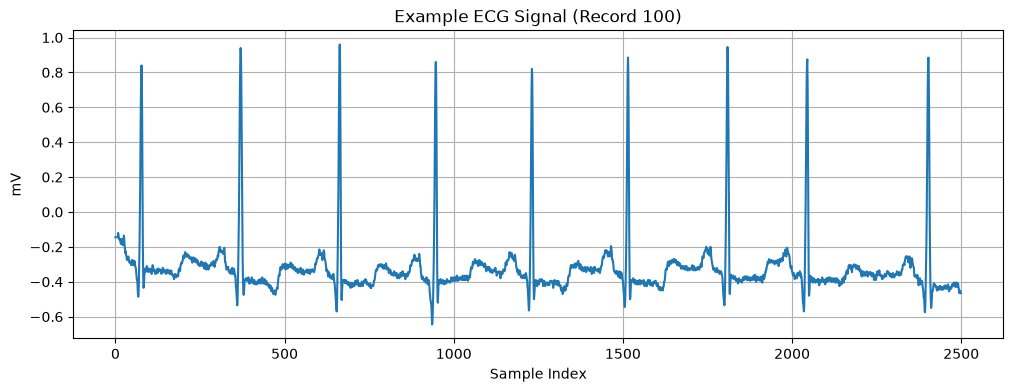

In [2]:
import wfdb
import matplotlib.pyplot as plt

record = wfdb.rdrecord('/Users/marcus/Desktop/mit-bih-arrhythmia-database-1.0.0/100')

signal = record.p_signal[:, 0]  # MLII channel

plt.figure(figsize=(12,4))
plt.plot(signal[:2500])
plt.title("Example ECG Signal (Record 100)")
plt.xlabel("Sample Index")
plt.ylabel("mV")
plt.grid(True)
plt.show()

Classes found:
N: Record 100
S: Record 100
V: Record 100
F: Record 108


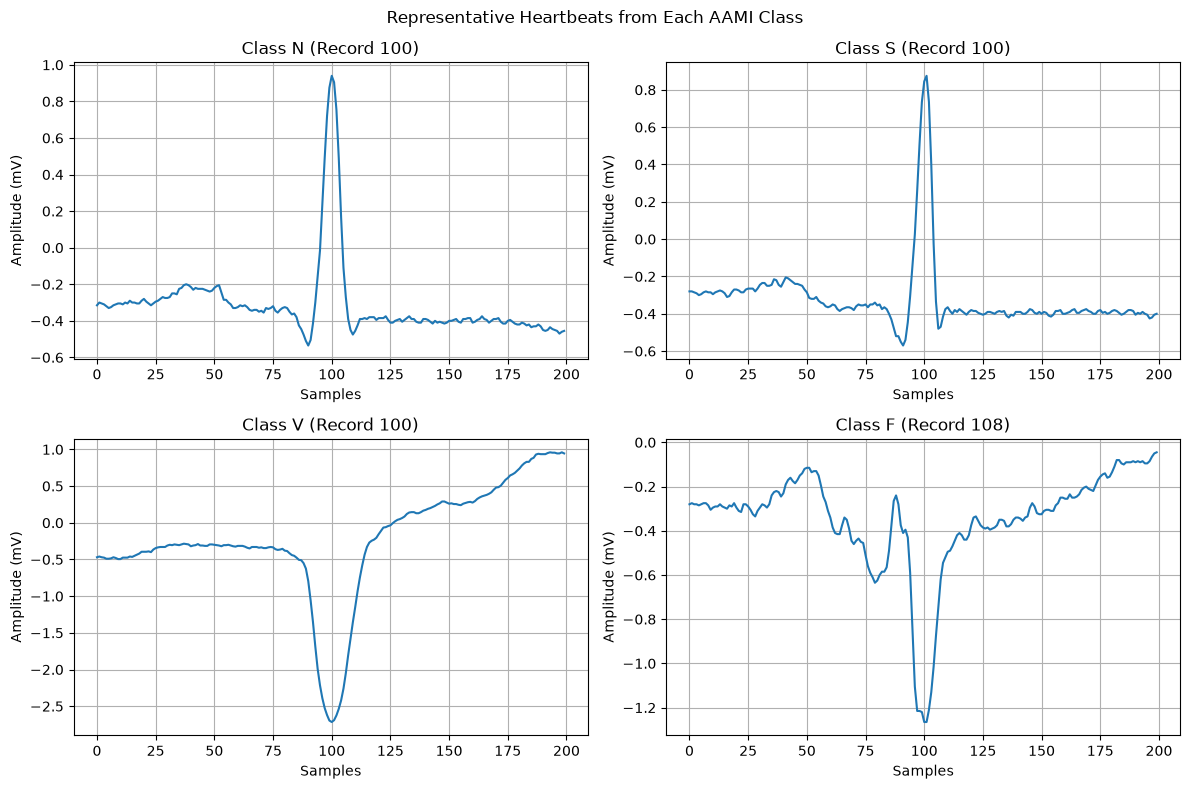

In [3]:
import wfdb
import matplotlib.pyplot as plt

# Path to MIT-BIH database
database_path = "/Users/marcus/Desktop/mit-bih-arrhythmia-database-1.0.0"

# MIT-BIH -> AAMI mapping
heartbeat_class_mapping = {
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
    'V': 'V', 'E': 'V',
    'F': 'F'
}

records = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

target_classes = ['N', 'S', 'V', 'F']
heartbeat_examples = {}

window = 100

for record_number in records:

    record = wfdb.rdrecord(f"{database_path}/{record_number}")
    annotations = wfdb.rdann(f"{database_path}/{record_number}", "atr")

    signal = record.p_signal[:, 0]

    for annotation_index, annotation_symbol in enumerate(annotations.symbol):

        if annotation_symbol not in heartbeat_class_mapping:
            continue

        heartbeat_class = heartbeat_class_mapping[annotation_symbol]

        if heartbeat_class in heartbeat_examples:
            continue

        peak_location = annotations.sample[annotation_index]

        # Make sure we can extract a full window
        if peak_location - window < 0:
            continue

        if peak_location + window >= len(signal):
            continue

        heartbeat_signal = signal[
            peak_location - window :
            peak_location + window
        ]

        heartbeat_examples[heartbeat_class] = {
            "record": record_number,
            "signal": heartbeat_signal
        }

    if len(heartbeat_examples) == 4:
        break

print("Classes found:")
for cls in heartbeat_examples:
    print(f"{cls}: Record {heartbeat_examples[cls]['record']}")

# Plot
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for axis, heartbeat_class in zip(axes.flatten(), target_classes):

    if heartbeat_class not in heartbeat_examples:
        axis.set_title(f"Class {heartbeat_class} Not Found")
        axis.axis("off")
        continue

    heartbeat_signal = heartbeat_examples[heartbeat_class]["signal"]
    record_number = heartbeat_examples[heartbeat_class]["record"]

    axis.plot(heartbeat_signal)
    axis.set_title(
        f"Class {heartbeat_class} (Record {record_number})"
    )
    axis.set_xlabel("Samples")
    axis.set_ylabel("Amplitude (mV)")
    axis.grid(True)

plt.suptitle("Representative Heartbeats from Each AAMI Class")
plt.tight_layout()
plt.show()

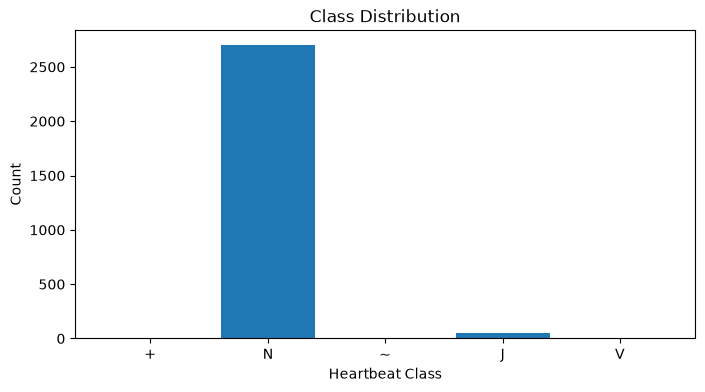

In [8]:
from collections import Counter
import matplotlib.pyplot as plt

symbols = ann.symbol

counts = Counter(symbols)

plt.figure(figsize=(8,4))
plt.bar(counts.keys(), counts.values())
plt.title("Class Distribution")
plt.xlabel("Heartbeat Class")
plt.ylabel("Count")
plt.show()

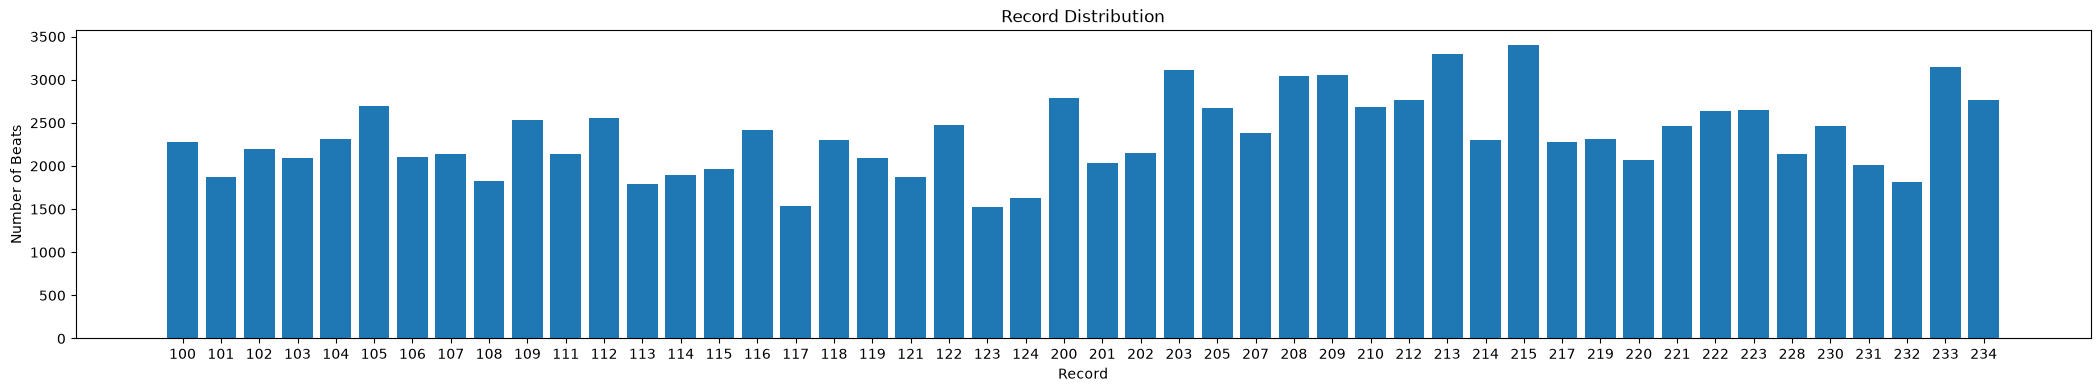

In [24]:
import os
import wfdb
import matplotlib.pyplot as plt

records = [
  "100", "101", "102", "103", "104", "105", "106", "107", "108", "109",
  "111", "112", "113", "114", "115", "116", "117", "118", "119", "121",
  "122", "123", "124", "200", "201", "202", "203", "205", "207", "208",
  "209", "210", "212", "213", "214", "215", "217", "219", "220", "221",
  "222", "223", "228", "230", "231", "232", "233", "234"
]

counts = []

for rec in records:
    ann = wfdb.rdann(f"/Users/marcus/Desktop/mit-bih-arrhythmia-database-1.0.0/{rec}", 'atr')
    counts.append(len(ann.sample))

plt.figure(figsize=(26,4))
plt.bar(records, counts)
plt.title("Record Distribution")
plt.xlabel("Record")
plt.ylabel("Number of Beats")
plt.show()

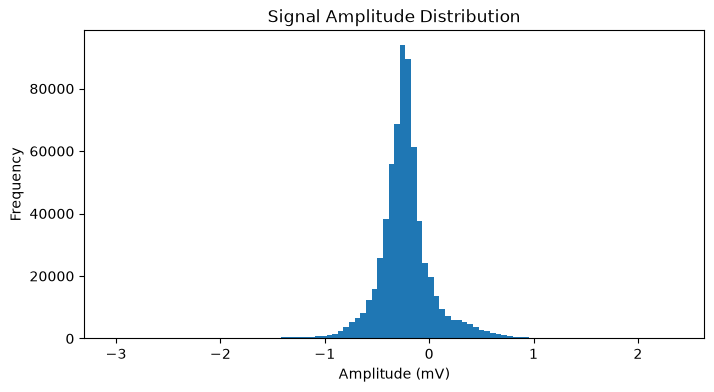

In [25]:
import matplotlib.pyplot as plt

signal = record.p_signal[:, 0]

plt.figure(figsize=(8,4))
plt.hist(signal, bins=100)
plt.title("Signal Amplitude Distribution")
plt.xlabel("Amplitude (mV)")
plt.ylabel("Frequency")
plt.show()

In [29]:
import wfdb
import numpy as np
import os
from collections import Counter

# MIT-BIH record IDs
record_ids = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

data_path = "/Users/marcus/Desktop/mit-bih-arrhythmia-database-1.0.0"

# Results
missing_data = []
extreme_amplitudes = []
corrupted_segments = []
recording_stats = []
channel_stats = []
noisy_regions = []
all_classes = []

for record_id in record_ids:

    record = wfdb.rdrecord(os.path.join(data_path, record_id))
    annotation = wfdb.rdann(os.path.join(data_path, record_id), "atr")

    signal = record.p_signal
    lead1 = signal[:, 0]

    # -------------------------
    # 1. Missing data
    # -------------------------
    if np.isnan(signal).any():
        missing_data.append(record_id)

    # -------------------------
    # 2. Extreme amplitudes
    # -------------------------
    peak_to_peak = np.ptp(lead1)

    if peak_to_peak > 10:
        extreme_amplitudes.append((record_id, peak_to_peak))

    # -------------------------
    # 3. Corrupted segments
    # -------------------------
    if np.isinf(signal).any():
        corrupted_segments.append(record_id)

    # -------------------------
    # 4. Class imbalance
    # -------------------------
    all_classes.extend(annotation.symbol)

    # -------------------------
    # 5. Differences between recordings
    # -------------------------
    recording_stats.append({
        "record": record_id,
        "mean": np.mean(lead1),
        "std": np.std(lead1),
        "range": peak_to_peak
    })

    # -------------------------
    # 6. Differences between ECG channels
    # -------------------------
    if signal.shape[1] >= 2:

        lead2 = signal[:, 1]

        channel_stats.append({
            "record": record_id,
            "lead1_std": np.std(lead1),
            "lead2_std": np.std(lead2),
            "correlation": np.corrcoef(lead1, lead2)[0, 1]
        })

    # -------------------------
    # 7. Possible noisy regions
    # -------------------------
    window_size = 3600  # 10 seconds

    for start in range(0, len(lead1)-window_size, window_size):

        segment = lead1[start:start+window_size]

        noise_level = np.std(np.diff(segment))

        if noise_level > 0.10:
            noisy_regions.append({
                "record": record_id,
                "sample_start": start,
                "noise": noise_level
            })

# ========================================
# Results
# ========================================

print("----- MISSING DATA -----")
print(f"Records with NaN values: {len(missing_data)}")

print("\n----- EXTREME AMPLITUDES -----")
print(f"Records flagged: {len(extreme_amplitudes)}")

print("\n----- CORRUPTED SEGMENTS -----")
print(f"Records with Inf values: {len(corrupted_segments)}")

print("\n----- CLASS IMBALANCE -----")
class_counts = Counter(all_classes)

for cls, count in class_counts.most_common():
    print(f"{cls}: {count}")

print("\n----- RECORDING DIFFERENCES -----")
ranges = [x['range'] for x in recording_stats]

print(f"Mean peak-to-peak range: {np.mean(ranges):.2f} mV")
print(f"Std peak-to-peak range: {np.std(ranges):.2f} mV")

print("\n----- CHANNEL DIFFERENCES -----")

if channel_stats:
    correlations = [x['correlation'] for x in channel_stats]

    print(
        f"Mean channel correlation: "
        f"{np.mean(correlations):.3f}"
    )

print("\n----- POSSIBLE NOISY REGIONS -----")
print(f"Flagged segments: {len(noisy_regions)}")


----- MISSING DATA -----
Records with NaN values: 0

----- EXTREME AMPLITUDES -----
Records flagged: 1

----- CORRUPTED SEGMENTS -----
Records with Inf values: 0

----- CLASS IMBALANCE -----
N: 75052
L: 8075
R: 7259
V: 7130
/: 7028
A: 2546
+: 1291
f: 982
F: 803
~: 616
!: 472
": 437
j: 229
x: 193
a: 150
|: 132
E: 106
J: 83
Q: 33
e: 16
[: 6
]: 6
S: 2

----- RECORDING DIFFERENCES -----
Mean peak-to-peak range: 5.06 mV
Std peak-to-peak range: 1.46 mV

----- CHANNEL DIFFERENCES -----
Mean channel correlation: -0.046

----- POSSIBLE NOISY REGIONS -----
Flagged segments: 308


In [ ]:
import wfdb
from collections import Counter
import matplotlib.pyplot as plt

# MIT-BIH records
record_ids = [
    '100','101','102','103','104','105','106','107','108','109',
    '111','112','113','114','115','116','117','118','119','121',
    '122','123','124','200','201','202','203','205','207','208',
    '209','210','212','213','214','215','217','219','220','221',
    '222','223','228','230','231','232','233','234'
]

data_path = "/Users/marcus/Desktop/mit-bih-arrhythmia-database-1.0.0"

def map_class(symbol):
    if symbol in ['N', 'L', 'R', 'e', 'j']:
        return 'N'
    elif symbol in ['A', 'a', 'J', 'S']:
        return 'S'
    elif symbol in ['V', 'E']:
        return 'V'
    elif symbol == 'F':
        return 'F'
    return None

# Store all mapped classes
all_classes = []

for record_id in record_ids:

    ann = wfdb.rdann(
        f"{data_path}/{record_id}",
        "atr"
    )

    for symbol in ann.symbol:

        mapped_class = map_class(symbol)

        if mapped_class is not None:
            all_classes.append(mapped_class)

# Count N, S, V, F
counts = Counter(all_classes)

print("Class Distribution:")
for cls in ['N', 'S', 'V', 'F']:
    print(f"{cls}: {counts[cls]}")

# Plot
plt.figure(figsize=(8, 4))
plt.bar(
    ['N', 'S', 'V', 'F'],
    [counts['N'], counts['S'], counts['V'], counts['F']],
    color='steelblue'
)

plt.title("MIT-BIH Class Distribution (N, S, V, F)")
plt.xlabel("Heartbeat Class")
plt.ylabel("Count")
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate([counts['N'], counts['S'], counts['V'], counts['F']]):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.show()